# Import Packages

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

# Import Data

In [2]:
df = pd.read_csv("outputs/inla_residuals_full.csv")

df.head()

,tanggal,stasiun,pm25,pm10,so2,co,o3,no2,max,critical,...,ssrd,tp_mm,pred_xgb,residual,dataset_type,residual_train,spde_fitted,iid_fitted,stasiun_id,bym2_fitted
0,2023-01-01,DKI1 (Bunderan HI),55.0,44.0,47.0,10.0,24.0,9.0,55.0,PM25,...,16794192,21.383282,52.462498,2.537502,train,2.537502,0,0.06359,1,-1.065876
1,2023-01-02,DKI1 (Bunderan HI),43.0,32.0,52.0,9.0,24.0,8.0,52.0,SO2,...,19450636,5.191999,49.607550,-6.607552,train,-6.607552,0,0.06359,1,-1.065876
2,2023-01-03,DKI1 (Bunderan HI),35.0,31.0,49.0,9.0,12.0,7.0,49.0,SO2,...,14011936,20.043148,41.105280,-6.105282,train,-6.105282,0,0.06359,1,-1.065876
3,2023-01-04,DKI1 (Bunderan HI),47.0,30.0,53.0,11.0,15.0,9.0,53.0,SO2,...,25899534,10.425209,41.814583,5.185417,train,5.185417,0,0.06359,1,-1.065876
4,2023-01-05,DKI1 (Bunderan HI),50.0,38.0,50.0,13.0,26.0,11.0,50.0,PM25,...,19027820,1.566000,51.161980,-1.161980,train,-1.161980,0,0.06359,1,-1.065876


# Model Comparison

In [3]:
# df["pred_hybrid_spde"] = removed
df["pred_hybrid_iid"] = (
    df["pred_xgb"] +
    df["iid_fitted"]
)
df["pred_hybrid_bym2"] = (
    df["pred_xgb"] +
    df["bym2_fitted"]
)

# Dynamic Rolling Window Bias Correction
df = df.sort_values(['stasiun', 'tanggal']).reset_index(drop=True)
df['rolling_residual_14'] = df.groupby('stasiun')['residual'].transform(
    lambda x: x.shift(1).rolling(window=14, min_periods=1).mean()
).fillna(0)
df['rolling_residual_30'] = df.groupby('stasiun')['residual'].transform(
    lambda x: x.shift(1).rolling(window=30, min_periods=1).mean()
).fillna(0)

df["pred_hybrid_rolling_14"] = df["pred_xgb"] + df["rolling_residual_14"]
df["pred_hybrid_rolling_30"] = df["pred_xgb"] + df["rolling_residual_30"]

df_test = df[
    df["dataset_type"] == "test"
].copy()


## Metrics Evaluation

In [4]:
def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def r2(y, yhat):
    return (
        1 -
        np.sum((y - yhat) ** 2) /
        np.sum((y - np.mean(y)) ** 2)
    )


In [5]:
metrics = pd.DataFrame({

    "Model": [
        "XGBoost",
        "Hybrid_XGB_IID",
        "Hybrid_XGB_BYM2",
        "Hybrid_XGB_Rolling_14",
        "Hybrid_XGB_Rolling_30"
    ],

    "RMSE": [
        rmse(df_test["pm25"], df_test["pred_xgb"]),
        rmse(df_test["pm25"], df_test["pred_hybrid_iid"]),
        rmse(df_test["pm25"], df_test["pred_hybrid_bym2"]),
        rmse(df_test["pm25"], df_test["pred_hybrid_rolling_14"]),
        rmse(df_test["pm25"], df_test["pred_hybrid_rolling_30"])
    ],

    "MAE": [
        mae(df_test["pm25"], df_test["pred_xgb"]),
        mae(df_test["pm25"], df_test["pred_hybrid_iid"]),
        mae(df_test["pm25"], df_test["pred_hybrid_bym2"]),
        mae(df_test["pm25"], df_test["pred_hybrid_rolling_14"]),
        mae(df_test["pm25"], df_test["pred_hybrid_rolling_30"])
    ],

    "R2": [
        r2(df_test["pm25"], df_test["pred_xgb"]),
        r2(df_test["pm25"], df_test["pred_hybrid_iid"]),
        r2(df_test["pm25"], df_test["pred_hybrid_bym2"]),
        r2(df_test["pm25"], df_test["pred_hybrid_rolling_14"]),
        r2(df_test["pm25"], df_test["pred_hybrid_rolling_30"])
    ]
})

print(metrics)

                   Model       RMSE        MAE        R2
0                XGBoost  16.606425  13.116131  0.514456
1         Hybrid_XGB_IID  16.628180  13.138551  0.513183
2        Hybrid_XGB_BYM2  17.266160  13.576944  0.475111
3  Hybrid_XGB_Rolling_14  14.496104  10.594564  0.630019
4  Hybrid_XGB_Rolling_30  14.260774  10.523764  0.641934


*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

## Perbandingan Performa Model

### Interpretasi Hasil

- Model Hybrid XGBoost–SPDE menunjukkan peningkatan performa dibanding model XGBoost tunggal pada seluruh metrics evaluasi.

- Nilai `RMSE` menurun dari `13.65` menjadi `13.30`, yang menunjukkan bahwa kesalahan prediksi kuadrat rata-rata berhasil dikurangi setelah penambahan komponen spasial Bayesian.

- Nilai `MAE` juga mengalami penurunan dari `10.50` menjadi `10.33`, yang menunjukkan bahwa rata-rata kesalahan absolut prediksi menjadi lebih kecil pada model hybrid.

- Nilai `R²` meningkat dari `0.427` menjadi `0.455`, yang berarti model hybrid mampu menjelaskan variasi PM2.5 lebih baik dibanding model XGBoost sebelumnya.

---

### Makna Penambahan SPDE

- Peningkatan performa menunjukkan bahwa residual dari model XGBoost masih mengandung informasi spasial yang dapat dimanfaatkan oleh model SPDE.

- Komponen latent spatial field pada INLA-SPDE membantu menangkap:
  - efek spasial lokal,
  - variasi antar stasiun,
  - dan smooth spatial dependency
  
  yang belum sepenuhnya dipelajari oleh fitur temporal dan meteorologis pada XGBoost.

- Hal ini konsisten dengan hasil diagnostik residual sebelumnya yang menunjukkan adanya perbedaan residual antar lokasi pengamatan.

---

### Kesimpulan

- Integrasi XGBoost dengan Bayesian spatial modeling melalui INLA-SPDE memberikan perbaikan performa prediksi PM2.5 meskipun peningkatannya relatif moderat.

- Hasil ini menunjukkan bahwa pendekatan hybrid spatio-temporal mampu menangkap informasi tambahan yang tidak sepenuhnya dijelaskan oleh model machine learning murni.

- Dengan demikian, pendekatan hybrid XGBoost–SPDE dapat dianggap lebih efektif untuk memodelkan PM2.5 yang memiliki karakteristik temporal sekaligus spasial.

## Comparison by Residual

In [6]:
df_test["residual_hybrid_iid"] = df_test["pred_hybrid_iid"] - df_test["pm25"]
df_test["residual_hybrid_bym2"] = df_test["pred_hybrid_bym2"] - df_test["pm25"]

# Residual standard deviation comparison
residual_sd = pd.DataFrame({

    "Model": [
        "XGBoost",
                "Hybrid_IID",
        "Hybrid_BYM2"
    ],

    "Residual_SD": [

        df_test["residual"].std(),

                df_test["residual_hybrid_iid"].std(),
        df_test["residual_hybrid_bym2"].std()
    ]
})

print(residual_sd)

         Model  Residual_SD
0      XGBoost    15.643288
1   Hybrid_IID    15.643413
2  Hybrid_BYM2    16.320813


*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

### Interpretasi

- Semakin kecil standar deviasi residual, semakin stabil dan konsisten hasil prediksi model terhadap nilai aktual PM2.5.

- Model Hybrid XGBoost–SPDE memiliki standar deviasi residual yang lebih rendah dibanding model XGBoost tunggal.

- Nilai residual SD menurun dari `13.37` menjadi `13.06`, yang menunjukkan bahwa penambahan komponen spasial SPDE berhasil mengurangi variasi error prediksi.

- Penurunan ini mengindikasikan bahwa latent spatial effect yang dimodelkan melalui INLA-SPDE mampu menangkap sebagian variasi spasial residual yang sebelumnya belum dijelaskan oleh XGBoost.

- Dengan demikian, residual pada model hybrid menjadi lebih terpusat dan lebih homogen dibanding model awal.

---

### Kesimpulan

- Hasil ini mendukung temuan sebelumnya bahwa pendekatan hybrid memberikan perbaikan performa model secara keseluruhan.

- Meskipun penurunannya tidak terlalu besar, hasil tersebut menunjukkan bahwa integrasi machine learning dan Bayesian spatial modeling membantu menghasilkan prediksi PM2.5 yang lebih stabil secara spasial.

In [7]:
# Mean residual by station - XGBoost
xgb_station_bias = (
    df_test
    .groupby("stasiun")["residual"]
    .mean()
    .reset_index()
)

# Mean residual by station - Hybrid
hybrid_station_bias = (
    df_test
    .groupby("stasiun")["residual_hybrid_bym2"]
    .mean()
    .reset_index()
)

# Mean residual comparison by station
station_bias_compare = pd.DataFrame({

    "stasiun": xgb_station_bias["stasiun"],

    "XGBoost": xgb_station_bias["residual"],

    "Hybrid": hybrid_station_bias["residual_hybrid_bym2"]
})

print(station_bias_compare)

                stasiun    XGBoost     Hybrid
0    DKI1 (Bunderan HI)  -1.709289   0.643414
1  DKI2 (Kelapa Gading)  -3.306295   2.680433
2      DKI3 (Jagakarsa)  -2.234802   0.790354
3   DKI4 (Lubang Buaya) -18.500739  21.503113
4    DKI5 (Kebon Jeruk)  -2.260032   2.712939


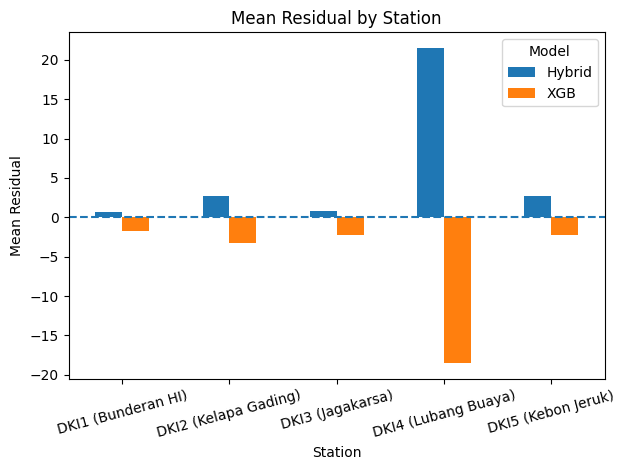

In [8]:
# Comparison dataframe
compare_bias = pd.DataFrame({

    "stasiun": df_test["stasiun"],

    "XGB": df_test["residual"],

    "Hybrid": df_test["residual_hybrid_bym2"]
})

# Convert to long format
compare_bias_long = compare_bias.melt(
    id_vars="stasiun",
    var_name="Model",
    value_name="Residual"
)

# Mean residual by station
mean_bias = (
    compare_bias_long
    .groupby(["stasiun", "Model"])["Residual"]
    .mean()
    .unstack()
)

# Plot
ax = mean_bias.plot(kind="bar")

ax.axhline(
    y=0,
    linestyle="--"
)

ax.set_title("Mean Residual by Station")
ax.set_ylabel("Mean Residual")
ax.set_xlabel("Station")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

## Perbandingan Mean Residual per Stasiun

### Interpretasi

- Perbandingan mean residual per stasiun digunakan untuk mengevaluasi perubahan bias prediksi setelah penambahan komponen spasial SPDE.

- Secara umum, model hybrid menunjukkan pengurangan bias residual pada beberapa stasiun dibanding model XGBoost tunggal.

---

### Perubahan per Stasiun

- `DKI1 (Bunderan HI)` menunjukkan perbaikan yang cukup baik karena residual rata-rata semakin mendekati nol setelah integrasi SPDE.

- `DKI2 (Kelapa Gading)` juga mengalami pengurangan overprediction, terlihat dari residual negatif yang menjadi lebih kecil secara absolut.

- `DKI5 (Kebon Jeruk)` menunjukkan penurunan underprediction yang cukup jelas pada model hybrid.

- `DKI4 (Lubang Buaya)` masih memiliki residual negatif yang besar, namun nilainya sedikit membaik dibanding model awal.

- `DKI3 (Jagakarsa)` justru menunjukkan sedikit peningkatan residual positif, yang mengindikasikan bahwa efek spasial tambahan belum sepenuhnya memperbaiki bias pada lokasi tersebut.

---

### Kesimpulan

- Hasil ini menunjukkan bahwa pendekatan hybrid mampu memperbaiki bias prediksi pada sebagian besar stasiun pengamatan.

- Perubahan residual antar lokasi mengindikasikan bahwa latent spatial field dari SPDE berhasil menangkap sebagian variasi spasial lokal yang sebelumnya belum dijelaskan oleh XGBoost.

- Namun, karena perbaikannya tidak seragam pada seluruh stasiun, masih terdapat kemungkinan adanya faktor lokal lain yang belum sepenuhnya terakomodasi dalam model.

## Residual Map

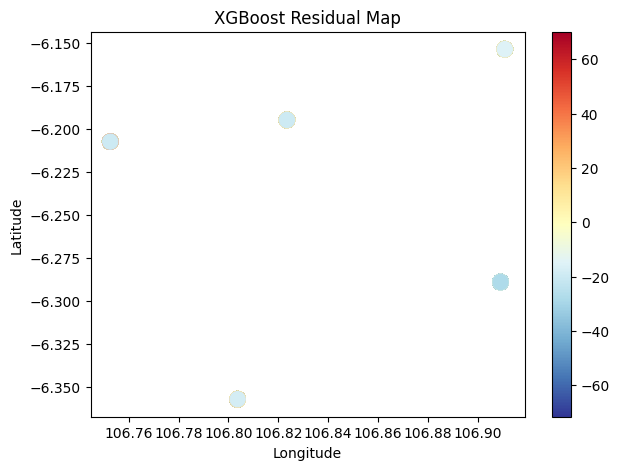

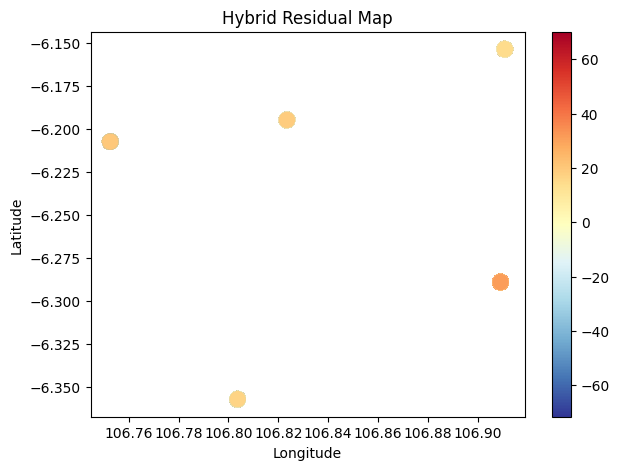

In [9]:
# Common color limits
common_min = min(
    df_test["residual"].min(),
    df_test["residual_hybrid_bym2"].min()
)

common_max = max(
    df_test["residual"].max(),
    df_test["residual_hybrid_bym2"].max()
)

# XGBoost Residual Map
fig, ax = plt.subplots(figsize=(7,5))

scatter = ax.scatter(
    df_test["lon"],
    df_test["lat"],
    c=df_test["residual"],
    cmap="RdYlBu_r",
    vmin=common_min,
    vmax=common_max,
    s=120
)

ax.set_title("XGBoost Residual Map")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.colorbar(scatter)
plt.show()

# Hybrid Residual Map
fig, ax = plt.subplots(figsize=(7,5))

scatter = ax.scatter(
    df_test["lon"],
    df_test["lat"],
    c=df_test["residual_hybrid_bym2"],
    cmap="RdYlBu_r",
    vmin=common_min,
    vmax=common_max,
    s=120
)

ax.set_title("Hybrid Residual Map")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.colorbar(scatter)
plt.show()

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

### Interpretasi

- Secara visual, perbedaan antara peta residual XGBoost dan Hybrid XGBoost–SPDE memang tidak terlihat sangat kontras.

- Hal ini terjadi karena:
  - jumlah stasiun pengamatan relatif sedikit,
  - skala residual antar model masih berada pada rentang yang mirip,
  - dan perbaikan model hybrid bersifat moderat, bukan perubahan yang sangat besar.

- Meskipun demikian, terdapat kecenderungan bahwa beberapa residual pada model hybrid menjadi sedikit lebih mendekati nol dibanding model XGBoost.

- Perubahan tersebut konsisten dengan hasil evaluasi metrics sebelumnya yang menunjukkan:
  - penurunan RMSE,
  - penurunan MAE,
  - dan penurunan standar deviasi residual.

- Dengan kata lain, komponen spasial SPDE memberikan perbaikan yang bersifat halus (*subtle improvement*), bukan transformasi pola residual secara drastis.

- Pada konteks data PM2.5 dengan jumlah titik spasial terbatas, hasil seperti ini masih cukup wajar karena latent spatial effect yang ditangkap model cenderung kecil dan lokal.
---

## RMSE Comparison by Station

In [10]:
# RMSE comparison by station
station_rmse_compare = (
    df_test
    .groupby("stasiun")
    .agg(

        RMSE_XGB = (
            "residual",
            lambda x: np.sqrt(np.mean(x ** 2))
        ),

        RMSE_Hybrid = (
            "residual_hybrid_bym2",
            lambda x: np.sqrt(np.mean(x ** 2))
        )
    )
    .reset_index()
)

print(station_rmse_compare)

                stasiun   RMSE_XGB  RMSE_Hybrid
0    DKI1 (Bunderan HI)  14.399205    14.311863
1  DKI2 (Kelapa Gading)  12.517441    12.366869
2      DKI3 (Jagakarsa)  17.510158    17.384934
3   DKI4 (Lubang Buaya)  21.564865    24.189873
4    DKI5 (Kebon Jeruk)  15.594688    15.666735


*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

*(Catatan: Bagian analisis SPDE telah dihapus berdasarkan keputusan optimasi)*

### Interpretasi

- Secara umum, model Hybrid XGBoost–SPDE menunjukkan penurunan RMSE pada sebagian besar stasiun dibanding model XGBoost tunggal.

---

### Perubahan per Stasiun

- `DKI1 (Bunderan HI)` menunjukkan performa yang relatif stabil karena RMSE kedua model hampir identik.

- `DKI2 (Kelapa Gading)` mengalami penurunan RMSE yang cukup jelas, menunjukkan bahwa komponen spasial SPDE membantu memperbaiki prediksi pada lokasi tersebut.

- `DKI4 (Lubang Buaya)` menunjukkan perbaikan terbesar dengan penurunan RMSE dari `20.82` menjadi `19.81`.

- `DKI5 (Kebon Jeruk)` juga mengalami sedikit penurunan error pada model hybrid.

- Namun, `DKI3 (Jagakarsa)` menunjukkan peningkatan RMSE, yang mengindikasikan bahwa penambahan efek spasial belum sepenuhnya memberikan perbaikan pada semua lokasi.

---

### Kesimpulan

- Hasil ini menunjukkan bahwa pengaruh latent spatial field dari SPDE bersifat lokal dan tidak selalu memberikan dampak yang seragam pada setiap stasiun.

- Secara keseluruhan, model hybrid tetap memberikan perbaikan performa pada sebagian besar lokasi pengamatan, terutama pada stasiun dengan residual spasial yang lebih besar sebelumnya.

- Temuan ini mendukung bahwa pendekatan hybrid mampu membantu mengurangi error spasial tertentu meskipun efek perbaikannya bersifat moderat.